In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load dataset
df = pd.read_csv("../dataset/Online Retail.csv", encoding="ISO-8859-1")

df.head()

# Display first 5 rows
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,01-12-2010 08:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,01-12-2010 08:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,01-12-2010 08:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,01-12-2010 08:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,01-12-2010 08:26,3.39,17850.0,United Kingdom


In [10]:
# Dataset dimensions
print("Dataset Shape:", df.shape)

# Column names
print("\nColumn Names:")
print(df.columns.tolist())

# Dataset information
print("\nDataset Information:")
df.info()

# Missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Duplicate records
print("\nDuplicate Records:", df.duplicated().sum())

Dataset Shape: (541909, 8)

Column Names:
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  str    
 1   StockCode    541909 non-null  str    
 2   Description  540455 non-null  str    
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  str    
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      541909 non-null  str    
dtypes: float64(2), int64(1), str(5)
memory usage: 33.1 MB

Missing Values:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

Duplicate Records: 5268


In [12]:
# Check missing Customer IDs
print("Missing Customer IDs:", df['CustomerID'].isnull().sum())

# Remove rows with missing Customer IDs
df = df.dropna(subset=['CustomerID'])

# Remove cancelled transactions
df = df[~df['InvoiceNo'].astype(str).str.startswith('C')]

# Remove negative or zero quantities
df = df[df['Quantity'] > 0]

# Remove zero or negative prices
df = df[df['UnitPrice'] > 0]

# Convert InvoiceDate to datetime
df['InvoiceDate'] = pd.to_datetime(
    df['InvoiceDate'],
    format='%d-%m-%Y %H:%M'
)

# Remove duplicate records
df = df.drop_duplicates()

# Reset index
df = df.reset_index(drop=True)

print("Cleaned Dataset Shape:", df.shape)
print("Remaining Missing Values:", df.isnull().sum().sum())
print("Remaining Duplicates:", df.duplicated().sum())

Missing Customer IDs: 0
Cleaned Dataset Shape: (392692, 8)
Remaining Missing Values: 0
Remaining Duplicates: 0


In [13]:
# Calculate total amount for each transaction
df['TotalAmount'] = df['Quantity'] * df['UnitPrice']

# Set reference date
reference_date = df['InvoiceDate'].max() + pd.Timedelta(days=1)

# Create RFM table
rfm = df.groupby('CustomerID').agg({
    'InvoiceDate': lambda x: (reference_date - x.max()).days,
    'InvoiceNo': 'nunique',
    'TotalAmount': 'sum'
})

# Rename columns
rfm.rename(columns={
    'InvoiceDate': 'Recency',
    'InvoiceNo': 'Frequency',
    'TotalAmount': 'Monetary'
}, inplace=True)

# Display RFM data
rfm.head()

,Recency,Frequency,Monetary
CustomerID,,,
12346.0,326,1,77183.60
12347.0,2,7,4310.00
12348.0,75,4,1797.24
12349.0,19,1,1757.55
12350.0,310,1,334.40


In [14]:
# Display descriptive statistics
print(rfm.describe())

# Check missing values
print("\nMissing Values:")
print(rfm.isnull().sum())

# Check duplicate customers
print("\nDuplicate Customer IDs:", rfm.index.duplicated().sum())

           Recency    Frequency       Monetary
count  4338.000000  4338.000000    4338.000000
mean     92.536422     4.272015    2048.688081
std     100.014169     7.697998    8985.230220
min       1.000000     1.000000       3.750000
25%      18.000000     1.000000     306.482500
50%      51.000000     2.000000     668.570000
75%     142.000000     5.000000    1660.597500
max     374.000000   209.000000  280206.020000

Missing Values:
Recency      0
Frequency    0
Monetary     0
dtype: int64

Duplicate Customer IDs: 0


In [15]:
from sklearn.preprocessing import StandardScaler

# Select RFM features
rfm_features = rfm[['Recency', 'Frequency', 'Monetary']].copy()

# Standardize the data
scaler = StandardScaler()
rfm_scaled = scaler.fit_transform(rfm_features)

# Convert into DataFrame
rfm_scaled_df = pd.DataFrame(
    rfm_scaled,
    columns=['Recency', 'Frequency', 'Monetary'],
    index=rfm.index
)

rfm_scaled_df.head()

,Recency,Frequency,Monetary
CustomerID,,,
12346.0,2.334574,-0.425097,8.363010
12347.0,-0.905340,0.354417,0.251699
12348.0,-0.175360,-0.035340,-0.027988
12349.0,-0.735345,-0.425097,-0.032406
12350.0,2.174578,-0.425097,-0.190812


In [16]:
from sklearn.cluster import KMeans

# Calculate WCSS for different cluster numbers
wcss = []

for k in range(1, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    kmeans.fit(rfm_scaled_df)
    wcss.append(kmeans.inertia_)

print("WCSS Values:", wcss)

WCSS Values: [13014.000000000004, 9014.566279572977, 5441.3235868296615, 4096.300210662247, 3119.7898598001516, 2473.7933635647614, 2023.586627223549, 1717.0110430839188, 1468.7871021842977, 1281.0480511013266]


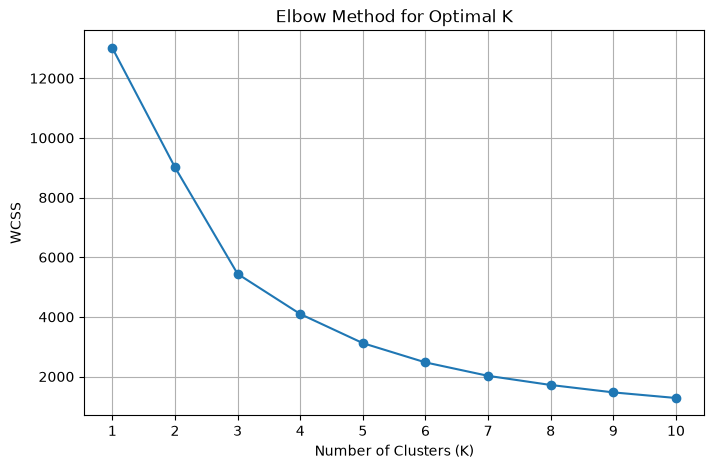

In [17]:
plt.figure(figsize=(8, 5))

plt.plot(range(1, 11), wcss, marker='o')

plt.title('Elbow Method for Optimal K')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('WCSS')
plt.xticks(range(1, 11))
plt.grid(True)

plt.savefig('../Output/elbow_method.png', dpi=300, bbox_inches='tight')
plt.show()

In [18]:
# Apply K-Means with 4 clusters
kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

# Assign cluster labels
rfm['Cluster'] = kmeans.fit_predict(rfm_scaled_df)

# Display first 10 customers
print(rfm.head(10))

# Count customers in each cluster
print("\nCustomers per Cluster:")
print(rfm['Cluster'].value_counts().sort_index())

            Recency  Frequency  Monetary  Cluster
CustomerID                                       
12346.0         326          1  77183.60        3
12347.0           2          7   4310.00        0
12348.0          75          4   1797.24        0
12349.0          19          1   1757.55        0
12350.0         310          1    334.40        1
12352.0          36          8   2506.04        0
12353.0         204          1     89.00        1
12354.0         232          1   1079.40        1
12355.0         214          1    459.40        1
12356.0          23          3   2811.43        0

Customers per Cluster:
Cluster
0    3054
1    1067
2      13
3     204
Name: count, dtype: int64


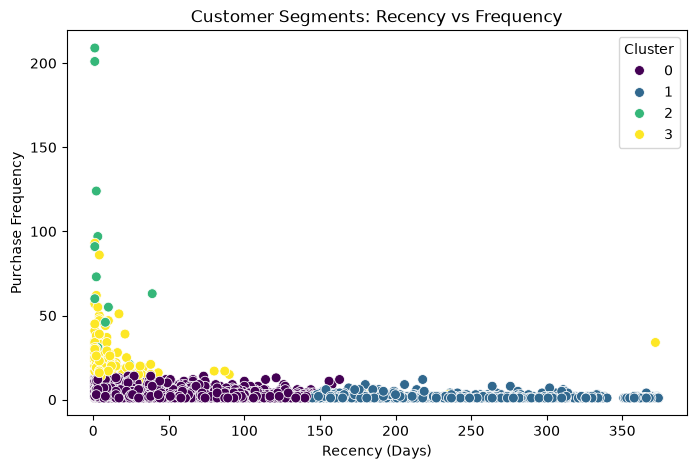

In [19]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=rfm,
    x='Recency',
    y='Frequency',
    hue='Cluster',
    palette='viridis',
    s=50
)

plt.title('Customer Segments: Recency vs Frequency')
plt.xlabel('Recency (Days)')
plt.ylabel('Purchase Frequency')
plt.savefig('../Output/recency_frequency_clusters.png',
            dpi=300, bbox_inches='tight')
plt.show()

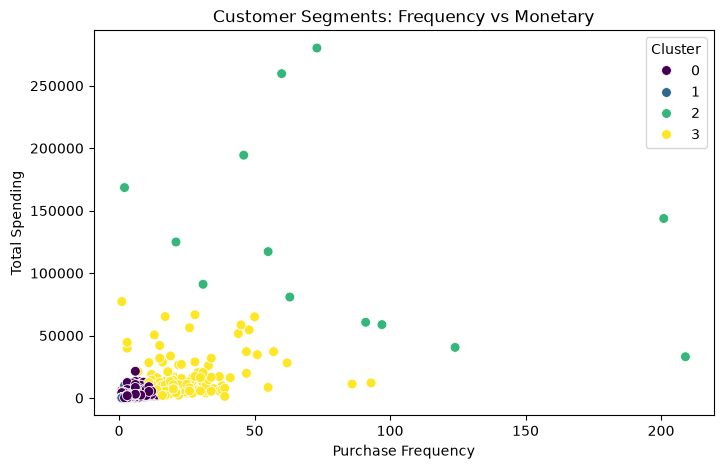

In [20]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=rfm,
    x='Frequency',
    y='Monetary',
    hue='Cluster',
    palette='viridis',
    s=50
)

plt.title('Customer Segments: Frequency vs Monetary')
plt.xlabel('Purchase Frequency')
plt.ylabel('Total Spending')
plt.savefig('../Output/frequency_monetary_clusters.png',
            dpi=300, bbox_inches='tight')
plt.show()

In [21]:
# Calculate average RFM values for each cluster
cluster_summary = rfm.groupby('Cluster').agg({
    'Recency': 'mean',
    'Frequency': 'mean',
    'Monetary': 'mean',
    'Cluster': 'count'
}).rename(columns={'Cluster': 'Customer_Count'})

print(cluster_summary.round(2))

         Recency  Frequency   Monetary  Customer_Count
Cluster                                               
0          43.70       3.68    1353.63            3054
1         248.08       1.55     478.85            1067
2           7.38      82.54  127187.96              13
3          15.50      22.33   12690.50             204


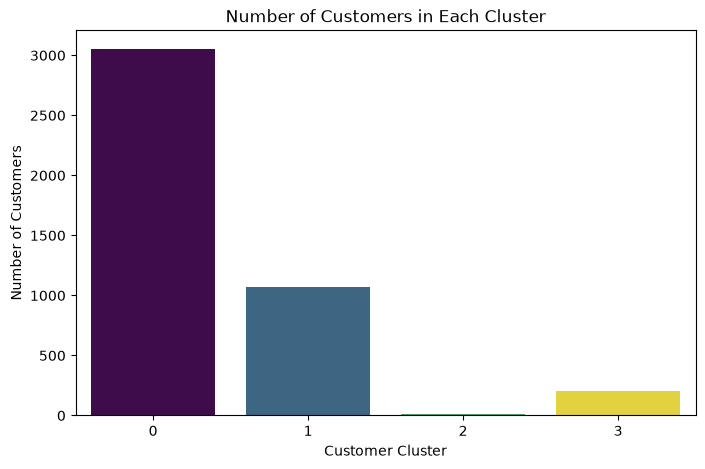

In [22]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=rfm,
    x='Cluster',
    hue='Cluster',
    palette='viridis',
    legend=False
)

plt.title('Number of Customers in Each Cluster')
plt.xlabel('Customer Cluster')
plt.ylabel('Number of Customers')

plt.savefig('../Output/customer_count_per_cluster.png',
            dpi=300, bbox_inches='tight')
plt.show()

In [23]:
print("CUSTOMER SEGMENTATION - KEY INSIGHTS")

print("\nTotal Customers:", len(rfm))
print("Total Clusters:", rfm['Cluster'].nunique())

print("\nCluster Distribution:")
print(rfm['Cluster'].value_counts().sort_index())

print("\nAverage Customer Spending:")
print(rfm.groupby('Cluster')['Monetary'].mean().round(2))

print("\nHighest Spending Cluster:",
      cluster_summary['Monetary'].idxmax())

print("\nMost Recent Purchasing Cluster:",
      cluster_summary['Recency'].idxmin())

CUSTOMER SEGMENTATION - KEY INSIGHTS

Total Customers: 4338
Total Clusters: 4

Cluster Distribution:
Cluster
0    3054
1    1067
2      13
3     204
Name: count, dtype: int64

Average Customer Spending:
Cluster
0      1353.63
1       478.85
2    127187.96
3     12690.50
Name: Monetary, dtype: float64

Highest Spending Cluster: 2

Most Recent Purchasing Cluster: 2


## Conclusion

Customer Segmentation Analysis was performed using the Online Retail dataset. The dataset was cleaned by removing missing customer IDs, cancelled transactions, invalid quantities, invalid prices, and duplicate records.

RFM analysis was used to calculate Recency, Frequency, and Monetary values for 4,338 customers. StandardScaler was applied to normalize the features, and the K-Means algorithm was used to divide customers into four clusters.

The analysis identified four customer groups:

1. Regular Customers – Customers with moderate purchasing activity.
2. At-Risk Customers – Customers who have not purchased for a long time.
3. VIP Customers – Customers with very high purchase frequency and spending.
4. Loyal Customers – Customers with recent and frequent purchases.

The results show that Cluster 2 has the highest average spending, while Cluster 0 contains the largest number of customers.

Businesses can use these segments to create targeted marketing campaigns, offer loyalty rewards, improve customer retention, and increase sales.

Overall, this project demonstrates how data analysis and machine learning can help businesses understand customer purchasing behaviour and make better marketing decisions.